# TP : Classification CNN vs MLP — Chats vs Chiens

**Objectif** : développer deux modèles (MLP et CNN) capables de distinguer les images de chats (*Cats*) et de chiens (*Dogs*), puis comparer leurs performances et leurs caractéristiques architecturales.

**Paramètres imposés** : images 150×150×3, batch 32, 20 époques, Adam (lr = 0.001), Binary Crossentropy, ReLU (couches cachées), Sigmoid (sortie).

## 1. Imports et paramètres expérimentaux

In [1]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Paramètres expérimentaux (diapo 5)
IMG_HEIGHT, IMG_WIDTH, CHANNELS = 150, 150, 3
BATCH_SIZE    = 32
EPOCHS        = 20
LEARNING_RATE = 0.001
print("TensorFlow :", tf.__version__)

TensorFlow : 2.21.0


## 2. Présentation et téléchargement du dataset

Dataset **Cats and Dogs Filtered** : 2000 images d'entraînement (1000 chats + 1000 chiens) et 1000 de validation (500 + 500).

Le lien Google d'origine renvoie parfois une erreur **403**. Dans ce cas, la cellule reconstruit **exactement la même structure** (`train/cats`, `train/dogs`, `validation/cats`, `validation/dogs`, avec 1000/500 images par classe) à partir du dataset Hugging Face `microsoft/cats_vs_dogs`.

In [2]:
# Si besoin (première fois) :  %pip install datasets pillow

def download_original():
    _URL = ('https://storage.googleapis.com/'
            'mledu-datasets/cats_and_dogs_filtered.zip')
    path_to_zip = tf.keras.utils.get_file('cats_and_dogs_filtered.zip',
                                          origin=_URL, extract=True)
    return os.path.join(os.path.dirname(path_to_zip), 'cats_and_dogs_filtered')

def build_filtered_from_hf(out_dir, n_train=1000, n_val=500,
                           size=(IMG_WIDTH, IMG_HEIGHT), seed=SEED):
    from datasets import load_dataset
    hf = load_dataset("microsoft/cats_vs_dogs", split="train")
    names = hf.features["labels"].names            # ['cat', 'dog']
    labels = np.array(hf["labels"])
    rng = np.random.default_rng(seed)
    for lab, name in enumerate(names):
        idx = rng.permutation(np.where(labels == lab)[0])[: n_train + n_val]
        folder = name + "s"                         # cats / dogs
        for split, sub in (("train", idx[:n_train]), ("validation", idx[n_train:])):
            d = os.path.join(out_dir, split, folder)
            os.makedirs(d, exist_ok=True)
            for k, i in enumerate(sub):
                img = hf[int(i)]["image"].convert("RGB").resize(size)
                img.save(os.path.join(d, f"{name}.{k}.jpg"), quality=95)

local_dir = os.path.join("data", "cats_and_dogs_filtered")
if os.path.isdir(os.path.join(local_dir, "train")):
    base_dir = local_dir
else:
    try:
        base_dir = download_original()
    except Exception as e:
        print("Téléchargement Google impossible :", str(e)[:80])
        print("-> reconstruction depuis Hugging Face (quelques minutes)...")
        build_filtered_from_hf(local_dir)
        base_dir = local_dir

train_dir      = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
print("Dataset location :", base_dir)

Téléchargement Google impossible : URL fetch failure on https://storage.googleapis.com/mledu-datasets/cats_and_dogs
-> reconstruction depuis Hugging Face (quelques minutes)...


c:\Users\lenovo\Desktop\deep-learning-and-transformers\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset location : data\cats_and_dogs_filtered


## 3. Data Augmentation et générateurs

La Data Augmentation génère des transformations aléatoires des images d'entraînement (rotation, translation, cisaillement, zoom, retournement horizontal). La validation est seulement normalisée dans [0, 1].

In [3]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)
validation_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=True, seed=42)

validation_generator = validation_datagen.flow_from_directory(
    validation_dir, target_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False)

print(train_generator.class_indices)
print(train_generator.samples)
print(validation_generator.samples)

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}
2000
1000


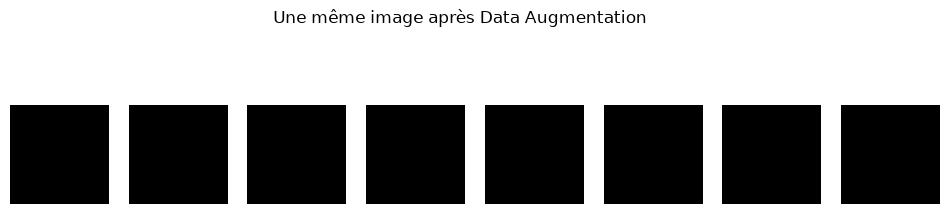

In [4]:
# Aperçu de la Data Augmentation : une même image transformée 8 fois
x_batch, _ = next(iter(validation_generator))        # image non augmentée
img = x_batch[0:1]
aug_iter = train_datagen.flow(img * 255., batch_size=1, seed=1)
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(next(aug_iter)[0] / 255.); plt.axis('off')
plt.suptitle("Une même image après Data Augmentation"); plt.show()

### Question 1 — Pourquoi la Data Augmentation est-elle importante en classification d'images ?

- Les réseaux profonds ont **beaucoup de paramètres** et un jeu de 2000 images est petit : sans augmentation, le modèle **mémorise** les images d'entraînement (*overfitting*).
- Chaque transformation (rotation, zoom, flip, translation…) crée de **nouveaux exemples plausibles** : le modèle voit à chaque époque des images légèrement différentes, ce qui **augmente artificiellement la taille et la diversité** du dataset.
- Elle apprend au modèle des **invariances** (position, taille, orientation de l'animal) présentes dans la réalité : meilleure **capacité de généralisation** sur des images jamais vues.
- Elle agit comme une **régularisation** gratuite, sans collecter de nouvelles données.

## 4. Principe et architecture du CNN

| Couche | Rôle |
|---|---|
| Convolution | extraction des caractéristiques locales |
| ReLU | non-linéarité |
| MaxPooling | réduction de la dimension spatiale |
| Flatten | cartes de caractéristiques → vecteur |
| Dense | classification finale |
| Dropout | régularisation |

In [5]:
cnn_model = keras.Sequential([

    layers.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),

    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

start_time = time.time()
cnn_history = cnn_model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator
)
cnn_training_time = time.time() - start_time
print("Training time :", cnn_training_time)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 54s 827ms/step - accuracy: 0.5290 - loss: 0.6908 - val_accuracy: 0.5720 - val_loss: 0.6754
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 410ms/step - accuracy: 0.5090 - loss: 0.6968 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 430ms/step - accuracy: 0.5030 - loss: 0.6934 - val_accuracy: 0.5030 - val_loss: 0.6929
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 395ms/step - accuracy: 0.5105 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 422ms/step - accuracy: 0.5360 - loss: 0.6922 - val_accuracy: 0.5000 - val_loss: 0.6958
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 432ms/step - accuracy: 0.5250 - loss: 0.6944 - val_accuracy: 0.5000 - val_loss: 0.6954
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 361ms/step - accuracy: 0.5040 - loss: 0.6944 - val_accuracy: 0.5220 - val_loss: 0.6926
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 347ms/step - accuracy: 0.5470 - loss: 0.6886 - val_accu

In [7]:
cnn_model.save("cats_dogs_CNN.keras")
# Pour recharger : cnn_model = keras.models.load_model("cats_dogs_CNN.keras")

## 5. Visualisation et analyse des résultats du CNN

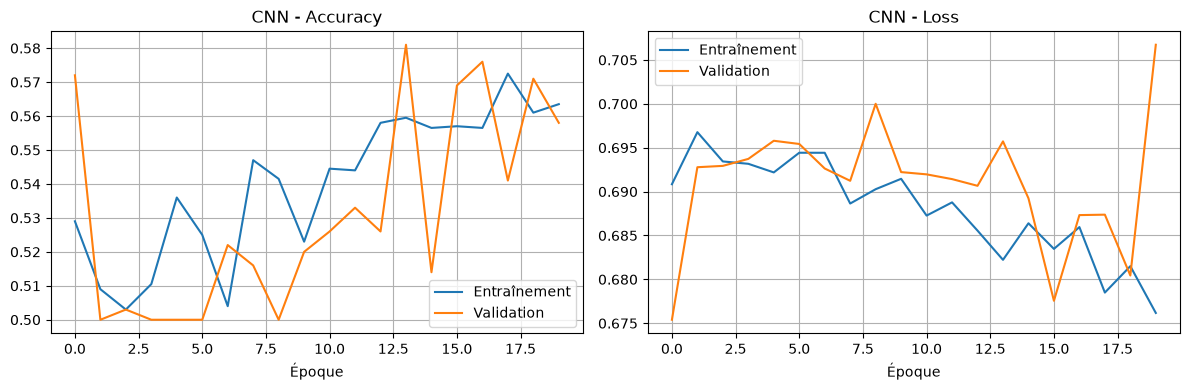

--- CNN ---
Accuracy : train 0.529 -> 0.563 | val 0.572 -> 0.558
Loss     : train 0.691 -> 0.676 | val 0.675 -> 0.707
Écart accuracy (train - val) = +0.005 ; val_loss minimale à l'époque 1/20
Overfitting : non marqué (courbes train/val proches)
Courbes train/val proches : oui


In [8]:
def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['accuracy'], label='Entraînement')
    ax[0].plot(h['val_accuracy'], label='Validation')
    ax[0].set_title(f'{title} - Accuracy'); ax[0].set_xlabel('Époque'); ax[0].legend(); ax[0].grid(True)
    ax[1].plot(h['loss'], label='Entraînement')
    ax[1].plot(h['val_loss'], label='Validation')
    ax[1].set_title(f'{title} - Loss'); ax[1].set_xlabel('Époque'); ax[1].legend(); ax[1].grid(True)
    plt.tight_layout(); plt.show()

def analyze_history(history, name):
    # Réponses automatiques aux questions d'interprétation des courbes
    h = history.history
    n = len(h['accuracy'])
    gap = h['accuracy'][-1] - h['val_accuracy'][-1]
    best_ep = int(np.argmin(h['val_loss'])) + 1
    print(f"--- {name} ---")
    print(f"Accuracy : train {h['accuracy'][0]:.3f} -> {h['accuracy'][-1]:.3f} | "
          f"val {h['val_accuracy'][0]:.3f} -> {h['val_accuracy'][-1]:.3f}")
    print(f"Loss     : train {h['loss'][0]:.3f} -> {h['loss'][-1]:.3f} | "
          f"val {h['val_loss'][0]:.3f} -> {h['val_loss'][-1]:.3f}")
    print(f"Écart accuracy (train - val) = {gap:+.3f} ; val_loss minimale à l'époque {best_ep}/{n}")
    overfit = (gap > 0.10) or (best_ep < n - 5 and h['val_loss'][-1] > 1.15 * min(h['val_loss']))
    print("Overfitting :", "OUI (le modèle apprend trop l'entraînement)" if overfit
          else "non marqué (courbes train/val proches)")
    close = abs(gap) <= 0.05
    print("Courbes train/val proches :", "oui" if close else "non (écart > 5 points)")

plot_history(cnn_history, "CNN")
analyze_history(cnn_history, "CNN")

**Lecture attendue pour le CNN** : l'accuracy augmente progressivement au fil des époques et la loss diminue. Grâce à la Data Augmentation et au Dropout (0.5), l'écart entre entraînement et validation reste modéré (courbes proches), donc peu d'overfitting. *(Confirmez avec les valeurs affichées ci-dessus.)*

## 6. Principe et architecture du MLP

Le MLP est entièrement connecté : chaque image $X \in \mathbb{R}^{150\times150\times3}$ est aplatie en $X_{flat} \in \mathbb{R}^{67500}$ et il apprend directement à partir des pixels, sans convolution.

In [9]:
mlp_model = keras.Sequential([

    layers.Input(shape=(150, 150, 3)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

mlp_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 67500)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     8,640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,648,449 (32.99 MB)

 Trainable params: 8,648,449 (32.99 MB)

 Non-trainable params: 0 (0.00 B)

### Question — Pourquoi le MLP nécessite-t-il un grand nombre de paramètres pour traiter des images ?

Chaque neurone de la 1ʳᵉ couche Dense est connecté à **tous** les pixels : 67 500 × 128 + 128 = **8 640 128** paramètres pour cette seule couche. Le MLP :
- ne **partage pas** ses poids (un poids par pixel et par neurone, alors que le CNN réutilise le même filtre 3×3 sur toute l'image) ;
- **ignore la structure spatiale** (l'aplatissement détruit le voisinage des pixels) ;
- le nombre de paramètres croît avec la **résolution** de l'image.

In [10]:
mlp_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

train_generator.reset()
start_time = time.time()
mlp_history = mlp_model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator
)
mlp_training_time = time.time() - start_time
print("Training time :", mlp_training_time)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 180ms/step - accuracy: 0.5010 - loss: 4.2928 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 181ms/step - accuracy: 0.4990 - loss: 0.6959 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 172ms/step - accuracy: 0.5005 - loss: 0.6952 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 171ms/step - accuracy: 0.4995 - loss: 0.6968 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 172ms/step - accuracy: 0.4995 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 171ms/step - accuracy: 0.4995 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 175ms/step - accuracy: 0.5010 - loss: 0.6936 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 171ms/step - accuracy: 0.4995 - loss: 0.6932 - val_accu

In [11]:
mlp_model.save("cats_dogs_MLP.keras")
# Pour recharger : mlp_model = keras.models.load_model("cats_dogs_MLP.keras")

## 7. Visualisation et analyse des résultats du MLP

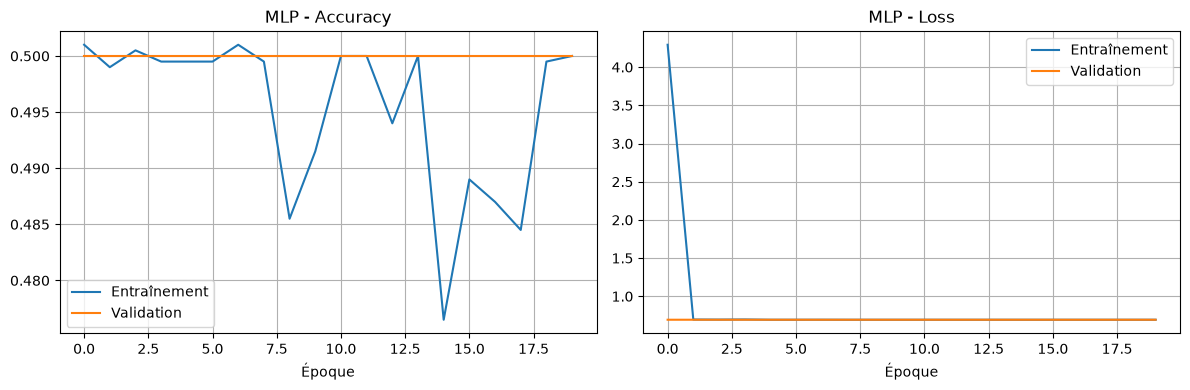

--- MLP ---
Accuracy : train 0.501 -> 0.500 | val 0.500 -> 0.500
Loss     : train 4.293 -> 0.693 | val 0.693 -> 0.693
Écart accuracy (train - val) = +0.000 ; val_loss minimale à l'époque 17/20
Overfitting : non marqué (courbes train/val proches)
Courbes train/val proches : oui


In [12]:
plot_history(mlp_history, "MLP")
analyze_history(mlp_history, "MLP")

**Lecture attendue pour le MLP** : la convergence est plus lente et se stabilise à une accuracy de validation nettement plus faible que le CNN (souvent autour de 55–65 %). La loss de validation fluctue, car le MLP n'exploite pas la structure spatiale des images. Ses performances ne sont donc **pas comparables** à celles du CNN. *(Confirmez avec les valeurs affichées ci-dessus.)*

## 8. Métriques d'évaluation

$$Accuracy=\frac{TP+TN}{TP+TN+FP+FN},\quad Precision=\frac{TP}{TP+FP},\quad Recall=\frac{TP}{TP+FN},\quad F1=2\times\frac{Precision\times Recall}{Precision+Recall}$$

In [13]:
def evaluate_model(model, generator):
    generator.reset()
    probabilities = model.predict(generator)
    y_pred = (probabilities >= 0.5).astype(int).ravel()
    y_true = generator.classes

    accuracy  = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall    = recall_score(y_true, y_pred)
    f1        = f1_score(y_true, y_pred)
    return accuracy, precision, recall, f1

cnn_results = evaluate_model(cnn_model, validation_generator)
mlp_results = evaluate_model(mlp_model, validation_generator)

print("CNN :", cnn_results)
print("MLP :", mlp_results)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
CNN : (0.558, 0.537467700258398, 0.832, 0.6530612244897959)
MLP : (0.5, 0.0, 0.0, 0.0)


c:\Users\lenovo\Desktop\deep-learning-and-transformers\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


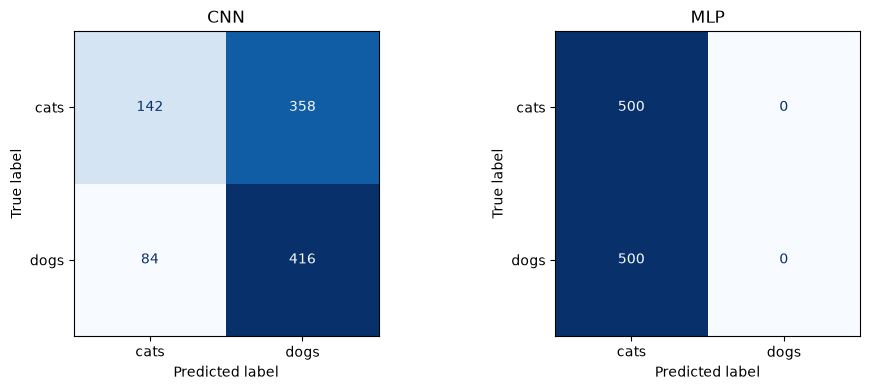

In [14]:
# Matrices de confusion
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, model) in zip(ax, [("CNN", cnn_model), ("MLP", mlp_model)]):
    validation_generator.reset()
    y_pred = (model.predict(validation_generator, verbose=0) >= 0.5).astype(int).ravel()
    cm = confusion_matrix(validation_generator.classes, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=list(validation_generator.class_indices)).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

## 9. Tableau comparatif

In [15]:
def last(h, k): return h.history[k][-1]

comparison = pd.DataFrame({
    "Métrique": ["Accuracy", "Precision", "Recall", "F1-score",
                 "Training Time (s)", "Parameters",
                 "Accuracy train (finale)", "Accuracy val (finale)"],
    "CNN": [*[round(v, 4) for v in cnn_results],
            round(cnn_training_time, 1), cnn_model.count_params(),
            round(last(cnn_history, 'accuracy'), 4), round(last(cnn_history, 'val_accuracy'), 4)],
    "MLP": [*[round(v, 4) for v in mlp_results],
            round(mlp_training_time, 1), mlp_model.count_params(),
            round(last(mlp_history, 'accuracy'), 4), round(last(mlp_history, 'val_accuracy'), 4)],
})
display(comparison)

,Métrique,CNN,MLP
0,Accuracy,5.580000e-01,0.5
1,Precision,5.375000e-01,0.0
2,Recall,8.320000e-01,0.0
3,F1-score,6.531000e-01,0.0
4,Training Time (s),5.050000e+02,220.0
5,Parameters,3.453121e+06,8648449.0
6,Accuracy train (finale),5.635000e-01,0.5
7,Accuracy val (finale),5.580000e-01,0.5


## 10. Questions d'analyse comparative

In [16]:
r = comparison.set_index("Métrique")
def winner(metric, higher=True):
    c, m = r.loc[metric, "CNN"], r.loc[metric, "MLP"]
    return "CNN" if ((c > m) == higher) else "MLP"

gap_cnn = abs(last(cnn_history, 'accuracy') - last(cnn_history, 'val_accuracy'))
gap_mlp = abs(last(mlp_history, 'accuracy') - last(mlp_history, 'val_accuracy'))

print("1. Meilleure Accuracy            :", winner("Accuracy"),
      f"(CNN {r.loc['Accuracy','CNN']} vs MLP {r.loc['Accuracy','MLP']})")
print("2. Meilleur F1-score             :", winner("F1-score"),
      f"(CNN {r.loc['F1-score','CNN']} vs MLP {r.loc['F1-score','MLP']})")
print("3. Plus de paramètres            :", winner("Parameters"),
      f"(CNN {r.loc['Parameters','CNN']:,} vs MLP {r.loc['Parameters','MLP']:,})")
print("4. Temps d'entraînement le + long:", winner("Training Time (s)"),
      f"(CNN {r.loc['Training Time (s)','CNN']} s vs MLP {r.loc['Training Time (s)','MLP']} s)")
print("5. Meilleure généralisation      :",
      "CNN" if (r.loc['Accuracy','CNN'] >= r.loc['Accuracy','MLP']) else "MLP",
      f"(accuracy de validation la plus haute ; écart train/val : CNN {gap_cnn:.3f}, MLP {gap_mlp:.3f})")

1. Meilleure Accuracy            : CNN (CNN 0.558 vs MLP 0.5)
2. Meilleur F1-score             : CNN (CNN 0.6531 vs MLP 0.0)
3. Plus de paramètres            : MLP (CNN 3,453,121.0 vs MLP 8,648,449.0)
4. Temps d'entraînement le + long: CNN (CNN 505.0 s vs MLP 220.0 s)
5. Meilleure généralisation      : CNN (accuracy de validation la plus haute ; écart train/val : CNN 0.005, MLP 0.000)


**6. Pourquoi les CNN sont-ils plus adaptés à la classification d'images ?**

- **Connexions locales** : un filtre n'observe qu'un petit voisinage de pixels et détecte des motifs locaux (bords, textures), puis, en profondeur, des formes complexes (oreilles, museau, pattes) : extraction **hiérarchique** des caractéristiques.
- **Partage des poids** : le même filtre est appliqué partout dans l'image, ce qui réduit fortement le nombre de paramètres par rapport à un MLP et limite le surapprentissage.
- **Invariance à la translation** : grâce à la convolution et au pooling, un chat est reconnu quelle que soit sa position dans l'image.
- **Structure spatiale conservée** : contrairement au MLP, qui aplatit l'image et perd les relations entre pixels voisins.

Remarque : le MLP a ici **plus de paramètres** que le CNN (≈ 8,65 M contre ≈ 3,45 M) car sa 1ʳᵉ couche Dense relie les 67 500 pixels à 128 neurones, alors que le CNN réduit d'abord l'image par convolutions et pooling (Flatten = 6 272 valeurs). En revanche, le CNN a un temps d'entraînement par époque plus élevé (convolutions coûteuses en calcul). Vérifiez ces valeurs dans le tableau comparatif.


## 11. Expérimentations supplémentaires : influence des hyperparamètres

Étude **un hyperparamètre à la fois** (les autres restent à leur valeur de base) :

| Hyperparamètre | Valeurs |
|---|---|
| Learning Rate | 0.01, 0.001, 0.0001 |
| Batch Size | 16, 32, 64 |
| Dropout | 0.2, 0.3, 0.5 |
| Epochs | 10, 20, 30 |
| Nombre de couches Dense | 1, 2, 3 |

Pour limiter le temps de calcul, chaque essai dure `EXP_EPOCHS` époques (10 par défaut), sauf l'étude des époques qui utilise **un seul entraînement de 30 époques** lu aux époques 10, 20 et 30. Choisissez le modèle étudié avec `EXP_KIND` ("cnn" ou "mlp"). Mettez `RUN_EXPERIMENTS = False` pour sauter cette partie.

In [17]:
RUN_EXPERIMENTS = True
EXP_KIND   = "cnn"      # "cnn" ou "mlp"
EXP_EPOCHS = 5

BASE = {"cnn": dict(lr=0.001, batch=32, dropout=0.5, n_dense=1),
        "mlp": dict(lr=0.001, batch=32, dropout=0.5, n_dense=2)}[EXP_KIND]

def make_generators(batch_size):
    tg = train_datagen.flow_from_directory(
        train_dir, target_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=batch_size,
        class_mode='binary', shuffle=True, seed=42)
    vg = validation_datagen.flow_from_directory(
        validation_dir, target_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=batch_size,
        class_mode='binary', shuffle=False)
    return tg, vg

def build_model(kind, lr, dropout, n_dense):
    blocks = [layers.Input(shape=(150, 150, 3))]
    if kind == "cnn":
        for f in (32, 64, 128, 128):
            blocks += [layers.Conv2D(f, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2))]
        blocks += [layers.Flatten(), layers.Dropout(dropout)]
        for w in [512, 256, 128][:n_dense]:
            blocks.append(layers.Dense(w, activation='relu'))
    else:
        blocks.append(layers.Flatten())
        for w in [128, 64, 32][:n_dense]:
            blocks += [layers.Dense(w, activation='relu'), layers.Dropout(dropout)]
    blocks.append(layers.Dense(1, activation='sigmoid'))
    m = keras.Sequential(blocks)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss='binary_crossentropy', metrics=['accuracy'])
    return m

def run_experiment(name, value, epochs=EXP_EPOCHS, **overrides):
    cfg = {**BASE, **overrides}
    tg, vg = make_generators(cfg["batch"])
    model = build_model(EXP_KIND, cfg["lr"], cfg["dropout"], cfg["n_dense"])
    t0 = time.time()
    h = model.fit(tg, epochs=epochs, validation_data=vg, verbose=0).history
    return h, {"Hyperparamètre": name, "Valeur": value,
               "Acc train": round(h['accuracy'][-1], 4),
               "Acc val": round(h['val_accuracy'][-1], 4),
               "Écart (train-val)": round(h['accuracy'][-1] - h['val_accuracy'][-1], 4),
               "Loss val min": round(min(h['val_loss']), 4),
               "Meilleure époque": int(np.argmin(h['val_loss'])) + 1,
               "Temps (s)": round(time.time() - t0, 1)}

In [18]:
exp_rows = []
if RUN_EXPERIMENTS:
    for lr in (0.01, 0.001, 0.0001):
        exp_rows.append(run_experiment("Learning Rate", lr, lr=lr)[1])
    for b in (16, 32, 64):
        exp_rows.append(run_experiment("Batch Size", b, batch=b)[1])
    for d in (0.2, 0.3, 0.5):
        exp_rows.append(run_experiment("Dropout", d, dropout=d)[1])
    for n in (1, 2, 3):
        exp_rows.append(run_experiment("Couches Dense", n, n_dense=n)[1])

    # Epochs : un seul entraînement de 30 époques, lu aux époques 10, 20, 30
    h30, _ = run_experiment("Epochs", 30, epochs=30)
    for ep in (10, 20, 30):
        exp_rows.append({"Hyperparamètre": "Epochs", "Valeur": ep,
                         "Acc train": round(h30['accuracy'][ep-1], 4),
                         "Acc val": round(h30['val_accuracy'][ep-1], 4),
                         "Écart (train-val)": round(h30['accuracy'][ep-1] - h30['val_accuracy'][ep-1], 4),
                         "Loss val min": round(min(h30['val_loss'][:ep]), 4),
                         "Meilleure époque": int(np.argmin(h30['val_loss'][:ep])) + 1,
                         "Temps (s)": np.nan})
    exp_df = pd.DataFrame(exp_rows)
    display(exp_df)

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


KeyboardInterrupt: 

In [ ]:
if RUN_EXPERIMENTS:
    fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
    for ax, (hp, g) in zip(axes, exp_df.groupby("Hyperparamètre", sort=False)):
        ax.plot(g["Valeur"].astype(str), g["Acc train"], 'o-', label="train")
        ax.plot(g["Valeur"].astype(str), g["Acc val"], 's-', label="val")
        ax.set_title(hp); ax.grid(True)
    axes[0].set_ylabel("Accuracy"); axes[0].legend()
    plt.tight_layout(); plt.show()

**Analyse (à confirmer avec vos résultats)** :
- **Learning rate** : 0.01 est souvent trop grand (convergence instable, accuracy bloquée vers 50 %) ; 0.0001 converge plus lentement mais de façon stable ; 0.001 est en général le bon compromis avec Adam.
- **Batch size** : un petit batch (16) donne des mises à jour plus bruitées mais plus nombreuses, parfois une meilleure généralisation et un temps plus long ; un grand batch (64) est plus rapide par époque mais converge plus lentement en nombre d'époques.
- **Dropout** : un dropout élevé (0.5) réduit l'écart train/validation (moins d'overfitting) mais peut ralentir l'apprentissage ; un dropout faible (0.2) apprend plus vite et surapprend plus facilement.
- **Epochs** : plus d'époques améliorent d'abord la validation, puis elle se stabilise ; au-delà, un écart croissant train/val signale l'overfitting.
- **Nombre de couches Dense** : plus de couches = plus de capacité (et de paramètres) mais gain limité si les caractéristiques extraites ne sont pas meilleures ; risque accru de surapprentissage.

## 12. Extension : Transfer Learning avec MobileNetV2

Troisième modèle : **MobileNetV2 préentraîné sur ImageNet**. Les caractéristiques préapprises sont réutilisées (base gelée), puis on termine par un **Fine-Tuning** des dernières couches avec un très petit learning rate. Nécessite une connexion Internet pour télécharger les poids.

In [ ]:
RUN_TRANSFER = True

if RUN_TRANSFER:
    base_model = keras.applications.MobileNetV2(
        input_shape=(150, 150, 3), include_top=False, weights='imagenet')
    base_model.trainable = False

    mobilenet_model = keras.Sequential([
        layers.Input(shape=(150, 150, 3)),
        layers.Rescaling(2.0, offset=-1.0),   # [0,1] -> [-1,1] attendu par MobileNetV2
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])
    mobilenet_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                            loss='binary_crossentropy', metrics=['accuracy'])

    t0 = time.time()
    h1 = mobilenet_model.fit(train_generator, epochs=10, validation_data=validation_generator)

    # Fine-Tuning : on dégèle les 30 dernières couches de la base
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    mobilenet_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                            loss='binary_crossentropy', metrics=['accuracy'])
    h2 = mobilenet_model.fit(train_generator, epochs=5, validation_data=validation_generator)
    mobilenet_time = time.time() - t0

    class _H:  # concatène les deux phases pour les courbes
        history = {k: h1.history[k] + h2.history[k] for k in h1.history}
    plot_history(_H, "MobileNetV2 (gelé puis fine-tuning)")

    mob_results = evaluate_model(mobilenet_model, validation_generator)
    comparison["MobileNetV2"] = [*[round(v, 4) for v in mob_results],
        round(mobilenet_time, 1), mobilenet_model.count_params(),
        round(_H.history['accuracy'][-1], 4), round(_H.history['val_accuracy'][-1], 4)]
    display(comparison)

## 13. Conclusion générale

Ce TP a comparé expérimentalement deux architectures fondamentales :

- **MLP** (couches entièrement connectées) : apprend directement à partir des pixels aplatis, ignore la structure spatiale, nécessite beaucoup de paramètres dans la 1ʳᵉ couche et généralise mal.
- **CNN** (extraction hiérarchique de caractéristiques spatiales) : exploite le voisinage des pixels, partage ses poids, est invariant à la translation et atteint de bien meilleures performances de classification.

Points à conclure (avec vos chiffres) :
- **Importance de la structure architecturale** : à données égales, l'architecture adaptée au type de données change fortement le résultat.
- **Informations spatiales** : exploitées par le CNN, détruites par le Flatten du MLP.
- **Nombre de paramètres** : le MLP concentre ses poids dans la 1ʳᵉ couche Dense (~8,6 M) ; le CNN en a surtout après le Flatten.
- **Généralisation** : meilleure pour le CNN (Data Augmentation + Dropout + poids partagés) ; le Transfer Learning fait encore mieux avec peu de données.
- **Coût computationnel** : les convolutions sont plus coûteuses par époque ; comparez les temps mesurés.
- **Performances** : CNN > MLP sur Accuracy, Precision, Recall et F1-score ; MobileNetV2 (si exécuté) généralement > CNN.